# Titanic 🚢: Random Forest, Decision Trees and Kaggle Submission

## 1 · Import the tools

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

RANDOM_STATE = 42

## 2 · Load and inspect passenger records

In [3]:
titanic_data = pd.read_csv('train.csv')
print("Shape:", titanic_data.shape)
print("\nMissing values per column:")
print(titanic_data.isna().sum()[lambda s: s > 0])
print("\nSurvived class counts:")
print(titanic_data['Survived'].value_counts())
titanic_data.head()

Shape: (891, 12)

Missing values per column:
Age         177
Cabin       687
Embarked      2
dtype: int64

Survived class counts:
Survived
0    549
1    342
Name: count, dtype: int64


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


**Note:** The `train.csv` file contains the Kaggle training data (891 passengers, **with** the `Survived` label). The `Age` (177 missing values), `Cabin`, and `Embarked` columns contain missing values. We will use only 6 features: `Pclass`, `Sex`, `Age`, `SibSp`, `Parch`, and `Fare`.

## 3 · Part B: Prepare inputs and impute `Age` without leakage

1. **Data leakage in the original notebook:** The original code calculated the median age using the *entire dataset* before performing the split; consequently, information from the test rows leaked into the training data preparation process. The exercise instructions specify that the median must be derived solely from the training set—meaning the split should occur *before* imputation.
2. **No numerical difference in this specific dataset:** In this case, the median age is 28 whether calculated from the training set or the entire dataset. However, the flaw in the methodology remains; the fact that the values ​​happen to be identical here does not negate the issue, and with a different dataset, it could alter the results.
3. **Technical details:** While `dropna(subset=['Survived'])` has no effect on this dataset (as there are no missing labels), it is harmless. We use `.copy()` to avoid the `SettingWithCopyWarning`.

### Is it incorrect to further split the training data into a training set and a test set?

**No, it is not incorrect; in fact, it is necessary for this exercise.** The reason is that the Kaggle `test.csv` file **does not contain the `Survived` label**. Consequently, it cannot be used to calculate metrics such as accuracy, classification reports, confusion matrices, or recall, nor can it be used to compare different tree depths. For parts B through E, we must set aside a portion of the labeled data to evaluate the model. The exercise instructions themselves refer to a "training subset" and "both subsets."

In this notebook, there are two "test" sets, each serving a distinct purpose:

| | Source | Count | Labels | Purpose |
|:---|:---|:---:|:---:|:---|
| **Internal Test (Hold-out)** | 20% split from `train.csv` | 179 | Yes | Model evaluation and analysis (Parts B–E) |
| **Kaggle Test** | Official `test.csv` | 418 | No | Creating `submission.csv` and obtaining the final score (Part F) |

What *would* be incorrect is: (1) using information from the internal test set during the preparation of the training data (known as "data leakage")—which we prevented by performing the split *before* imputation; or (2) repeatedly tuning the model based on the internal test set and then reporting that specific result as the final accuracy. It is more precise to refer to this internal test set as a **validation** set, to avoid confusion with the official Kaggle `test.csv`.

In [4]:
titanic_data = titanic_data.dropna(subset=['Survived']).copy()
titanic_data['Sex'] = titanic_data['Sex'].map({'female': 0, 'male': 1})

features = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare']
X = titanic_data[features]
y = titanic_data['Survived']


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)


X_train = X_train.copy()
X_test = X_test.copy()
age_median = X_train['Age'].median()
X_train['Age'] = X_train['Age'].fillna(age_median)
X_test['Age'] = X_test['Age'].fillna(age_median)

print("Median age learned from training rows:", age_median)
print("Missing values left -> train:", int(X_train.isna().sum().sum()),
      "| test:", int(X_test.isna().sum().sum()))
print("Train size:", X_train.shape[0], "| Test size:", X_test.shape[0])

Median age learned from training rows: 28.0
Missing values left -> train: 0 | test: 0
Train size: 712 | Test size: 179


## 4 · Train a Random Forest classifier

In [5]:
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)
rf_classifier.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

### Predict example passengers

In [6]:
sample = X_test.iloc[[0]]
prediction = rf_classifier.predict(sample)
print(f"Sample passenger: {sample.iloc[0].to_dict()}")
print(f"Predicted: {'Survived' if prediction[0] == 1 else 'Did not survive'}")

jack = pd.DataFrame([{'Pclass': 3, 'Sex': 1, 'Age': 20, 'SibSp': 0, 'Parch': 0, 'Fare': 10}])
rose = pd.DataFrame([{'Pclass': 1, 'Sex': 0, 'Age': 17, 'SibSp': 0, 'Parch': 1, 'Fare': 50}])
print("Jack :", 'Survived' if rf_classifier.predict(jack[features])[0] == 1 else 'Did not survive')
print("Rose :", 'Survived' if rf_classifier.predict(rose[features])[0] == 1 else 'Did not survive')

Sample passenger: {'Pclass': 3.0, 'Sex': 1.0, 'Age': 28.0, 'SibSp': 1.0, 'Parch': 1.0, 'Fare': 15.2458}
Predicted: Did not survive
Jack : Did not survive
Rose : Survived


## 5 · Part A: Feature importance

1. **Copy-paste error in the problem statement:** The phrase "predicting a *comedian's rank*" has been carried over from a previous exercise (involving comedians). This dataset contains neither a `Rank` column nor any comedians; the objective is to predict **passenger survival (`Survived`)**. We interpret the problem accordingly.
2. **Method validity:** In a Random Forest, `feature_importances_` is based on **impurity reduction** and exhibits a bias toward continuous features with a large number of unique values ​​(such as `Fare` and `Age`). Consequently, it may incorrectly rank `Fare` as more important than `Sex`—a result that contradicts domain knowledge (the "women and children first" principle). To ensure a more accurate assessment, we also include **permutation importance** calculated on the test set.

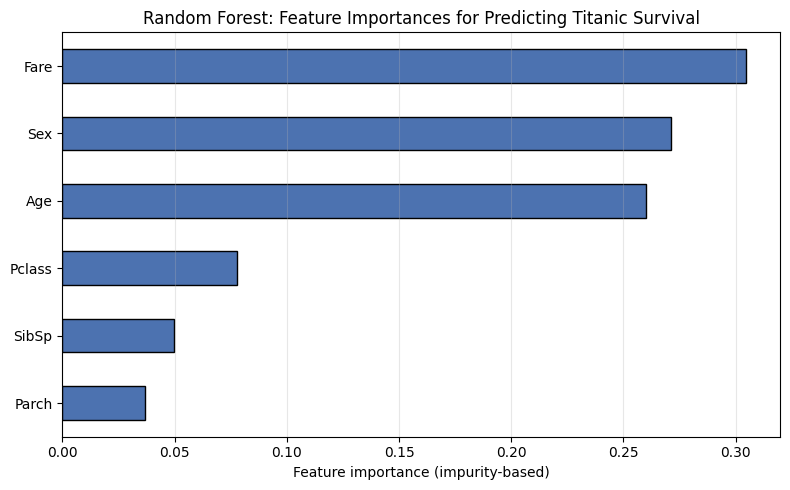

,importance
Fare,0.3046
Sex,0.2713
Age,0.2600
Pclass,0.0778
SibSp,0.0495
Parch,0.0368


In [7]:
importances = pd.Series(rf_classifier.feature_importances_, index=features).sort_values()

plt.figure(figsize=(8, 5))
importances.plot(kind='barh', color='#4C72B0', edgecolor='k')
plt.xlabel('Feature importance (impurity-based)')
plt.title('Random Forest: Feature Importances for Predicting Titanic Survival')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

display(importances.sort_values(ascending=False).round(4).to_frame('importance'))

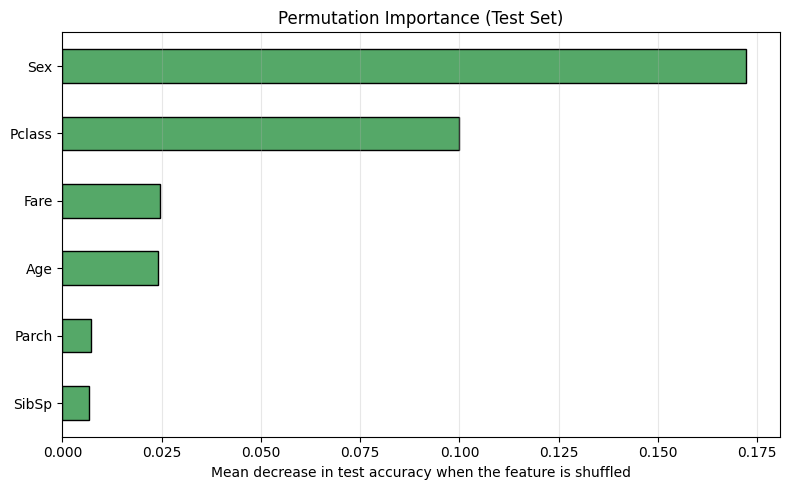

,permutation importance
Sex,0.1721
Pclass,0.1000
Fare,0.0246
Age,0.0240
Parch,0.0073
SibSp,0.0067


In [8]:
perm = permutation_importance(rf_classifier, X_test, y_test, n_repeats=10,
                              random_state=RANDOM_STATE)
perm_imp = pd.Series(perm.importances_mean, index=features).sort_values()

plt.figure(figsize=(8, 5))
perm_imp.plot(kind='barh', color='#55A868', edgecolor='k')
plt.xlabel('Mean decrease in test accuracy when the feature is shuffled')
plt.title('Permutation Importance (Test Set)')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

display(perm_imp.sort_values(ascending=False).round(4).to_frame('permutation importance'))

**Interpretation:** In the first chart (based on impurity), `Fare` (approx. 0.30), `Sex` (approx. 0.27), and `Age` (approx. 0.26) rank at the top, while `Pclass`, `SibSp`, and `Parch` are of lesser importance. However, when looking at permutation importance on the test data, the ranking shifts: `Sex` (approx. 0.17) and `Pclass` (approx. 0.10) emerge as the most significant factors—by a considerable margin—whereas `Fare` and `Age` show values ​​of only about 0.02. This discrepancy suggests that the high importance attributed to `Fare` and `Age` in the first chart is largely a result of the impurity-based method’s inherent bias toward continuous features. A more accurate conclusion—one that aligns with domain knowledge (i.e., that "women and passengers in higher classes were given priority")—is that **gender and passenger class** are the most critical predictors of survival.

## 6 · Part C: Classification report and confusion matrix

The original notebook displayed the labels as `Class 0` and `Class 1`, which are not very descriptive. The problem statement requires the labels `Did not survive` and `Survived`; we apply these to both the report (via `target_names`) and the matrix (via `display_labels`). In the matrix, the rows represent the **actual** classes, while the columns represent the **predicted** classes.

Test accuracy: 0.7989

                 precision    recall  f1-score   support

Did not survive       0.82      0.85      0.83       105
       Survived       0.77      0.73      0.75        74

       accuracy                           0.80       179
      macro avg       0.79      0.79      0.79       179
   weighted avg       0.80      0.80      0.80       179



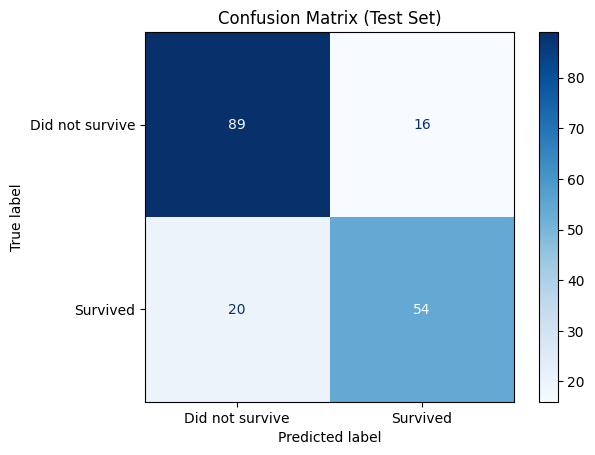

In [9]:
labels = ['Did not survive', 'Survived']

y_pred = rf_classifier.predict(X_test)
print("Test accuracy:", round(accuracy_score(y_test, y_pred), 4))
print()
print(classification_report(y_test, y_pred, target_names=labels))

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix (Test Set)')
plt.show()

## 7 · Part D: False positives, false negatives and recall

In [10]:
tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
print(f"True Negatives  (did not survive, predicted did not survive): {tn}")
print(f"False Positives (did not survive, predicted survived)       : {fp}")
print(f"False Negatives (survived, predicted did not survive)       : {fn}")
print(f"True Positives  (survived, predicted survived)              : {tp}")
print()
print(f"Recall 'Did not survive': {tn / (tn + fp):.4f}")
print(f"Recall 'Survived'      : {tp / (tp + fn):.4f}")
print(f"Share of 'Did not survive' in test set: {(y_test == 0).mean():.2%}")

True Negatives  (did not survive, predicted did not survive): 89
False Positives (did not survive, predicted survived)       : 16
False Negatives (survived, predicted did not survive)       : 20
True Positives  (survived, predicted survived)              : 54

Recall 'Did not survive': 0.8476
Recall 'Survived'      : 0.7297
Share of 'Did not survive' in test set: 58.66%


**Answer:** When "survived" is the positive class:

- **False Positive (FP):** The model predicts a passenger "survived," when in reality, they **did not survive**.
- **False Negative (FN):** The model predicts a passenger "did not survive," when in reality, they **survived**.

In our execution (`random_state=42`): 89 TNs, 16 FPs, 20 FNs, and 54 TPs. The "Did not survive" class has a higher recall (approximately 0.85, compared to about 0.73 for "Survived") because it is the majority class (making up about 60% of the data), and the model has encountered more examples of it. Consequently, the model is more prone to errors when **identifying passengers who survived** (the number of FNs is higher than the number of FPs).

## 8 · Part E: Limiting the depth of a Decision Tree

1. **Flawed Metric:** Comparing depths based solely on **training accuracy** is misleading, as training accuracy *always* increases as the tree grows deeper (due to data memorization). To ensure a fair assessment, we have also included a **Test Accuracy** column.
2. **Actual Depth ≠ Maximum Depth:** `max_depth` serves only as an upper limit; if all leaf nodes become pure sooner, the tree stops growing earlier. For this reason, the "Actual Depth" is reported separately.

In [11]:
rows = []
trees = {}
for d in [1, 2, 4, 8]:
    dt = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE)
    dt.fit(X_train, y_train)
    trees[d] = dt
    rows.append({
        'Max Depth': d,
        'Actual Depth': dt.get_depth(),
        'Number of Leaves': dt.get_n_leaves(),
        'Training Accuracy': dt.score(X_train, y_train),
        'Test Accuracy': dt.score(X_test, y_test),   # extra column (see critical note 2)
    })

depth_df = pd.DataFrame(rows)
display(depth_df.round(4))

,Max Depth,Actual Depth,Number of Leaves,Training Accuracy,Test Accuracy
0,1,1,2,0.7879,0.7821
1,2,2,4,0.8034,0.7654
2,4,4,15,0.8385,0.7989
3,8,8,64,0.9003,0.7933


In [12]:
for d in [1, 2]:
    print(f"--- Decision rules for max_depth={d} ---")
    print(export_text(trees[d], feature_names=features))

--- Decision rules for max_depth=1 ---
|--- Sex <= 0.50
|   |--- class: 1
|--- Sex >  0.50
|   |--- class: 0

--- Decision rules for max_depth=2 ---
|--- Sex <= 0.50
|   |--- Pclass <= 2.50
|   |   |--- class: 1
|   |--- Pclass >  2.50
|   |   |--- class: 0
|--- Sex >  0.50
|   |--- Age <= 6.50
|   |   |--- class: 1
|   |--- Age >  6.50
|   |   |--- class: 0



**Answer:** As the tree grows deeper, the number of leaves increases from 2 to 64, and the training accuracy rises from approximately 0.79 to about 0.90. However, the test accuracy ceases to improve beyond a depth of 4; this is a sign of **overfitting**.

- At **depth 1**, the tree makes decisions based solely on gender (`Sex`).
- At **depth 2**, rules involving `Pclass` (for women) and `Age` (for men—specifically children under about 6.5 years old) are added.
- At **depth 8**, the rules become highly granular and specific to the training data, whereas a simple rule based on "gender, class, and age" yields roughly the same test accuracy while being more interpretable.

## 9 · Part F: Create `submission.csv` for Kaggle

1. **"Test predictions" has two meanings:** In the notebook, "test" refers to the 20% subset separated from `train.csv` (179 passengers). However, Kaggle requires predictions for the **official `test.csv`** (418 unlabeled passengers); submitting output based on the internal split will be rejected. Therefore, we must generate the submission file using the official `test.csv`.
2. **A new missing value:** There is a missing value in the `Fare` column of `test.csv` that does not appear in the training set; this must be filled using the median from the **training set** (not the median from the test set).
3. **"Test accuracy" cannot be calculated locally:** The labels for `test.csv` are hidden; accuracy is calculated by Kaggle only after submission.
4. **Final model:** For the submission, we retrain the model on the **entire labeled dataset** (891 rows) and derive the imputation values ​​exclusively from that same data.

In [ ]:
TEST_PATH = Path('test.csv')

X_full = titanic_data[features].copy()
y_full = titanic_data['Survived']
age_median_full = X_full['Age'].median()
fare_median_full = X_full['Fare'].median()
X_full['Age'] = X_full['Age'].fillna(age_median_full)

final_rf = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)
final_rf.fit(X_full, y_full)

kaggle_test = pd.read_csv(TEST_PATH)
kaggle_test['Sex'] = kaggle_test['Sex'].map({'female': 0, 'male': 1})
X_kaggle = kaggle_test[features].copy()
X_kaggle['Age'] = X_kaggle['Age'].fillna(age_median_full)
X_kaggle['Fare'] = X_kaggle['Fare'].fillna(fare_median_full)   # test.csv has 1 missing Fare

submission = pd.DataFrame({
    'PassengerId': kaggle_test['PassengerId'],
    'Survived': final_rf.predict(X_kaggle).astype(int),
})

assert submission.shape == (418, 2), f"Unexpected shape: {submission.shape}"
assert list(submission.columns) == ['PassengerId', 'Survived']
assert submission['Survived'].isin([0, 1]).all()
assert submission['PassengerId'].is_unique
    assert not X_kaggle.isna().any().any(), "NaN values remain in test features"

    submission.to_csv('submission.csv', index=False)
    print("Saved submission.csv", submission.shape)
    display(submission.head())

Saved submission.csv (418, 2)


,PassengerId,Survived
0,892,0
1,893,0
2,894,1
3,895,1
4,896,0


### [Link: Submission Score Titanic ](https://www.kaggle.com/competitions/titanic/leaderboard?search=ali+shahrouzi)



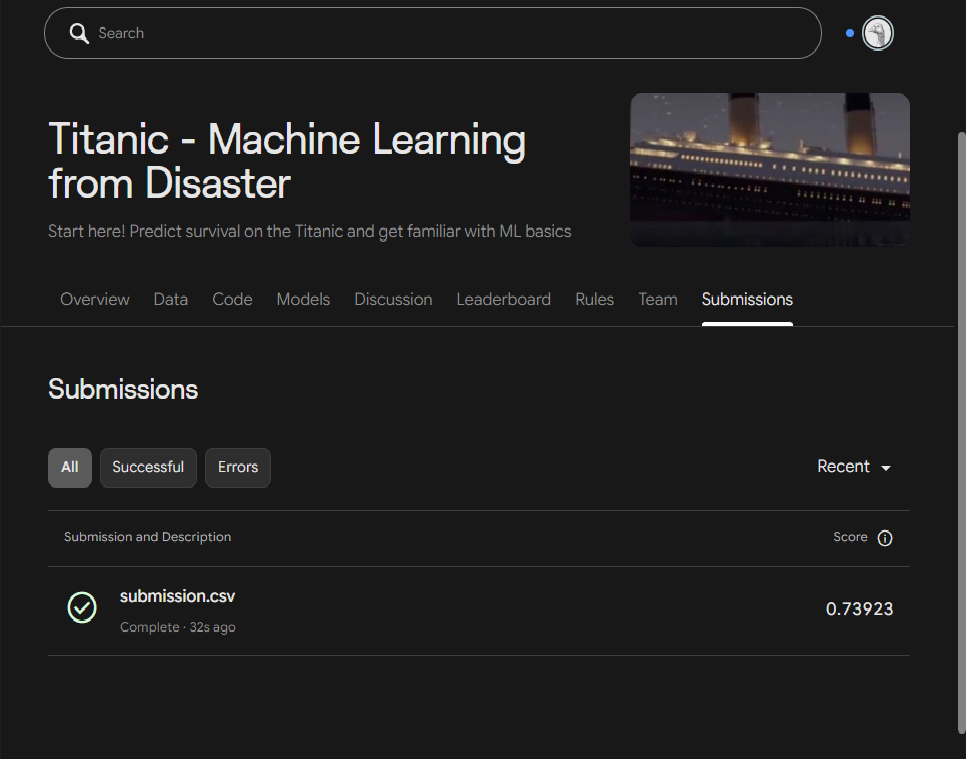

## Kaggle Submission Results

- **Kaggle Public Score (Accuracy):** **0.73923**
- **Internal Test Accuracy (80/20 split of `train.csv`):** 0.7989
- **Model:** Random Forest with `n_estimators=100` and `random_state=42`; features used: `Pclass`, `Sex`, `Age`, `SibSp`, `Parch`, `Fare`. Missing values ​​for `Age` and `Fare` were imputed using the median from the training data. The final model was trained on all 891 rows.

### Why is the Kaggle accuracy (0.739) lower than the internal accuracy (0.799)?

1. **Small Sample Size and Noise:** The internal test set contains only 179 passengers; the standard error for accuracy at this sample size is approximately 3% ($\sqrt{0.8 \times 0.2 / 179} \approx 0.03$). The Kaggle test set contains 418 passengers and carries its own inherent noise. Therefore, the ~6% difference could largely be due to random variation in sample selection, rather than a fundamental weakness in the model.
2. **Differences Between Datasets:** The internal test set and the Kaggle test set represent different samples of passengers, and their underlying distributions are not identical.
3. **Simple, Unoptimized Model:** The Random Forest was built using default parameters (with no depth constraints) and only 6 raw features. Potentially useful features—such as passenger titles (extracted from the `Name` column, e.g., Mr/Mrs/Miss), family size, or the `Embarked` port—were not included. As observed in Section E, deep trees tend to overfit.
4. **Comparison with Baseline:** The well-known score for the sample file `gender_submission.csv` (based solely on gender) is approximately 0.766—slightly higher than our score. This aligns with the findings in Section E (where a depth-1 tree using only the `Sex` feature yielded a test accuracy of about 0.78) and with the permutation importance analysis (which identified `Sex` as the most significant feature). In this dataset, employing a more complex model offers only marginal benefits.

**Conclusion:** The score of 0.73923 indicates that the model's actual accuracy on unseen data is slightly lower than the internal estimate. Consequently, the final reported accuracy should be based on the Kaggle results rather than the small internal test set.